# Do late deliveries hurt customer reviews, and are there any regions or delivery implications which are the biggest problems?

# Importing datasets

In [84]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import folium
import branca.colormap as cm
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from sklearn.metrics import RocCurveDisplay


In [ ]:
df_items = pd.read_csv("Olist data sets/olist_order_items_dataset.csv")
df_reviews = pd.read_csv("Olist data sets/olist_order_reviews_dataset.csv")
df_orders = pd.read_csv("Olist data sets/olist_orders_dataset.csv")
df_products = pd.read_csv("Olist data sets/olist_products_dataset.csv")
df_geolocation = pd.read_csv("Olist data sets/olist_geolocation_dataset.csv")
df_sellers = pd.read_csv("Olist data sets/olist_sellers_dataset.csv")
df_order_pay = pd.read_csv("Olist data sets/olist_order_payments_dataset.csv")
df_customers = pd.read_csv("Olist data sets/olist_customers_dataset.csv")
df_category = pd.read_csv("Olist data sets/product_category_name_translation.csv")

In [ ]:
# Some orders have multiple reviews, so we will take the latest review for each order
df_reviews_latest = (
    df_reviews.sort_values("review_answer_timestamp")
              .drop_duplicates(subset="order_id", keep="last")
)

df_main = pd.merge(df_reviews, df_orders, on="order_id", how="left")
df_main = pd.merge(df_main, df_customers, on="customer_id", how="left")

# Total item price per order (an order can contain several items)
# This is because df_main has one row per order, while df_items has one row per item
df_order_price = df_items.groupby("order_id", as_index=False)["price"].sum().rename(columns={"price": "order_price"})
df_main = pd.merge(df_main, df_order_price, on="order_id", how="left")

df_main.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   review_id                      99224 non-null  str    
 1   order_id                       99224 non-null  str    
 2   review_score                   99224 non-null  int64  
 3   review_comment_title           11568 non-null  str    
 4   review_comment_message         40977 non-null  str    
 5   review_creation_date           99224 non-null  str    
 6   review_answer_timestamp        99224 non-null  str    
 7   customer_id                    99224 non-null  str    
 8   order_status                   99224 non-null  str    
 9   order_purchase_timestamp       99224 non-null  str    
 10  order_approved_at              99068 non-null  str    
 11  order_delivered_carrier_date   97468 non-null  str    
 12  order_delivered_customer_date  96359 non-null  str    
 1

# Learning about our data set

In [8]:
df_main.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_price
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,41dcb106f807e993532d446263290104,delivered,2018-01-11 15:30:49,2018-01-11 15:47:59,2018-01-12 21:57:22,2018-01-17 18:42:41,2018-02-02 00:00:00,68a5590b9926689be4e10f4ae2db21a8,6030,osasco,SP,370.00
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,8a2e7ef9053dea531e4dc76bd6d853e6,delivered,2018-02-28 12:25:19,2018-02-28 12:48:39,2018-03-02 19:08:15,2018-03-09 23:17:20,2018-03-14 00:00:00,64190b91b656ab8f37eb89b93dc84584,13380,nova odessa,SP,79.79
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,e226dfed6544df5b7b87a48208690feb,delivered,2018-02-03 09:56:22,2018-02-03 10:33:41,2018-02-06 16:18:28,2018-02-16 17:28:48,2018-03-09 00:00:00,1d47144362c14e94ccdd213e8ec277d5,44571,santo antonio de jesus,BA,149.00
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,de6dff97e5f1ba84a3cd9a3bc97df5f6,delivered,2017-04-09 17:41:13,2017-04-09 17:55:19,2017-04-10 14:24:47,2017-04-20 09:08:35,2017-05-10 00:00:00,c8cf6cb6b838dc7a33ed199b825e8616,88735,gravatal,SC,179.99
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,5986b333ca0d44534a156a52a8e33a83,delivered,2018-02-10 10:59:03,2018-02-10 15:48:21,2018-02-15 19:36:14,2018-02-28 16:33:35,2018-03-09 00:00:00,d16000272660a1fef81482ad75ba572a,89520,curitibanos,SC,1199.00


In [9]:
df_main.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   review_id                      99224 non-null  str    
 1   order_id                       99224 non-null  str    
 2   review_score                   99224 non-null  int64  
 3   review_comment_title           11568 non-null  str    
 4   review_comment_message         40977 non-null  str    
 5   review_creation_date           99224 non-null  str    
 6   review_answer_timestamp        99224 non-null  str    
 7   customer_id                    99224 non-null  str    
 8   order_status                   99224 non-null  str    
 9   order_purchase_timestamp       99224 non-null  str    
 10  order_approved_at              99068 non-null  str    
 11  order_delivered_carrier_date   97468 non-null  str    
 12  order_delivered_customer_date  96359 non-null  str    
 1

In [10]:
df_main.describe()

,review_score,customer_zip_code_prefix,order_price
count,99224.000000,99224.000000,98465.000000
mean,4.086421,35157.108986,137.381047
std,1.347579,29823.027753,209.123667
min,1.000000,1003.000000,0.850000
25%,4.000000,11340.000000,45.900000
50%,5.000000,24415.000000,86.580000
75%,5.000000,59022.000000,149.900000
max,5.000000,99990.000000,13440.000000


In [11]:
df_main.columns.tolist()

['review_id',
 'order_id',
 'review_score',
 'review_comment_title',
 'review_comment_message',
 'review_creation_date',
 'review_answer_timestamp',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_zip_code_prefix',
 'customer_city',
 'customer_state',
 'order_price']

# Analysing the relationship between the delivery prediction accuracy and the review score

## Learning about delivery prediction accuracy

In [12]:
# Converting both columns to date-time format for further analysis
df_main["order_delivered_customer_date"] = pd.to_datetime(df_main["order_delivered_customer_date"])
df_main["order_estimated_delivery_date"] = pd.to_datetime(df_main["order_estimated_delivery_date"])


# Calculating the delivery delay in days
df_main["delivery_delay"] = (df_main["order_delivered_customer_date"] - df_main["order_estimated_delivery_date"]).dt.days


In [13]:
df_main["delivery_delay"].describe()

count    96359.000000
mean       -11.917797
std         10.114024
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: delivery_delay, dtype: float64

In [14]:
df_main["delivery_delay"].info()

<class 'pandas.Series'>
RangeIndex: 99224 entries, 0 to 99223
Series name: delivery_delay
Non-Null Count  Dtype  
--------------  -----  
96359 non-null  float64
dtypes: float64(1)
memory usage: 775.3 KB


In [15]:
df_main["delivery_delay"].value_counts()

delivery_delay
-14.0     7124
-13.0     5956
-15.0     5354
-7.0      4841
-8.0      4818
          ... 
 67.0        1
 80.0        1
-68.0        1
 138.0       1
-83.0        1
Name: count, Length: 196, dtype: int64

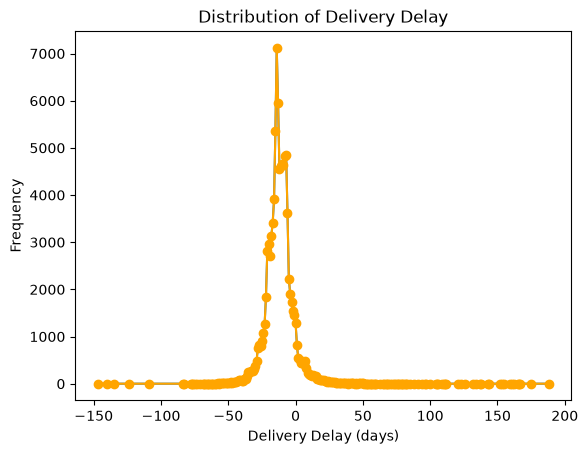

In [16]:
# Plotting the distribution of delivery delays
x = df_main["delivery_delay"].value_counts().sort_index().index
y = df_main["delivery_delay"].value_counts().sort_index().values
df_main["delivery_delay"].value_counts().sort_index().plot(
    kind="line",
    title="Distribution of Delivery Delay",
    xlabel="Delivery Delay (days)", 
    ylabel="Frequency")
plt.plot(x, y, marker='o', color='orange', label='Line of Best Fit')



You can see a bell curve shape in the distribution so I wanted to show this clearer

<Axes: xlabel='delivery_delay', ylabel='Density'>

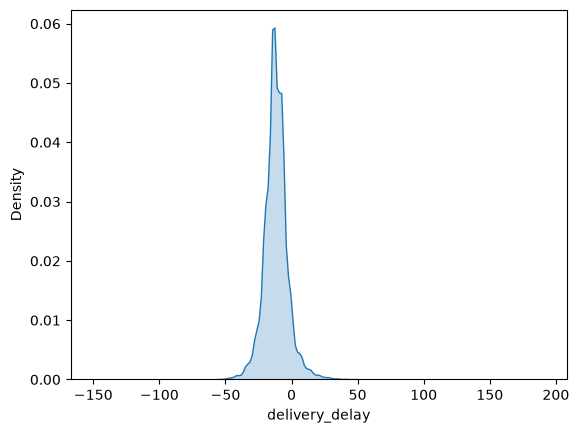

In [17]:
sns.kdeplot(df_main["delivery_delay"].dropna(), fill=True)

## Learning about review score

In [18]:
df_main["review_score"].value_counts()

review_score
5    57328
4    19142
1    11424
3     8179
2     3151
Name: count, dtype: int64

In [19]:
df_main["review_score"].describe()

count    99224.000000
mean         4.086421
std          1.347579
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64

In [20]:
df_main["review_score"].info()

<class 'pandas.Series'>
RangeIndex: 99224 entries, 0 to 99223
Series name: review_score
Non-Null Count  Dtype
--------------  -----
99224 non-null  int64
dtypes: int64(1)
memory usage: 775.3 KB


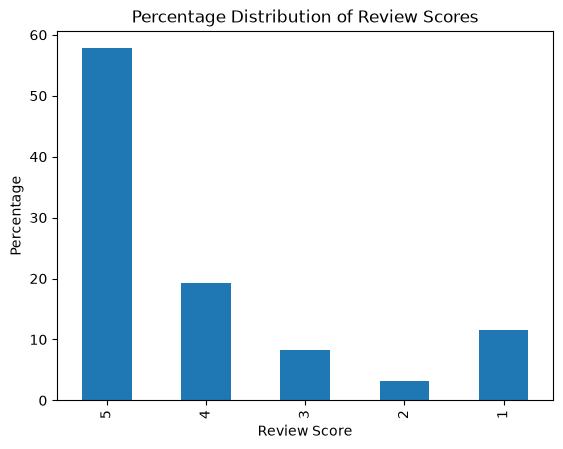

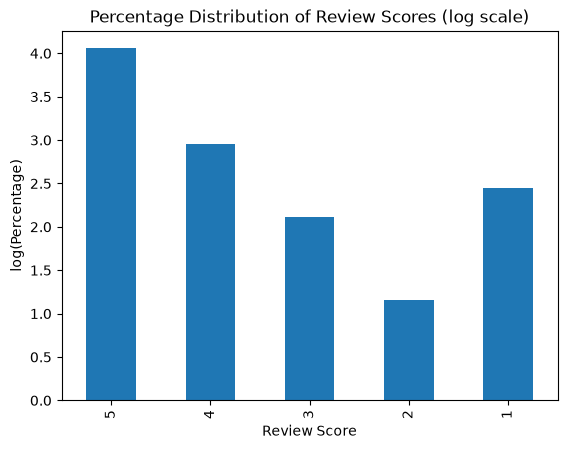

In [21]:
review_score_percentages = df_main["review_score"].value_counts(normalize=True) * 100

plt.figure()
review_score_percentages.sort_index(ascending=False).plot(
    kind="bar", title="Percentage Distribution of Review Scores", xlabel="Review Score", ylabel="Percentage")
plt.show()

plt.figure()
np.log(review_score_percentages).sort_index(ascending=False).plot(
    kind="bar", title="Percentage Distribution of Review Scores (log scale)", xlabel="Review Score", ylabel="log(Percentage)")
plt.show()

## Analysing the 2 columns

In [22]:
# Average delay for each review score
df_main.groupby("review_score")["delivery_delay"].mean()

review_score
1    -4.060580
2    -8.634818
3   -10.774052
4   -12.380840
5   -13.388153
Name: delivery_delay, dtype: float64

<Axes: title={'center': 'Average Delivery Delay by Review Score'}, xlabel='Review Score', ylabel='Average Delivery Delay (days)'>

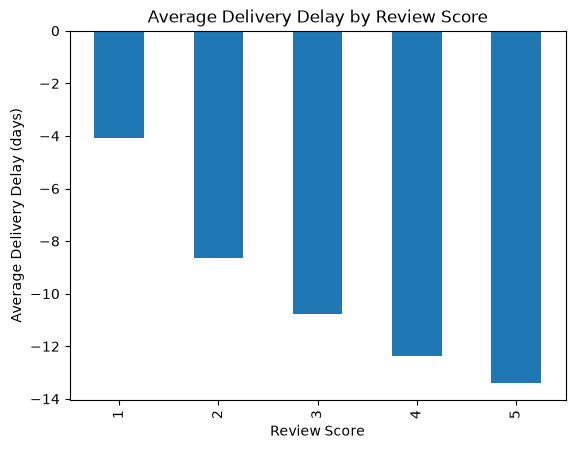

In [23]:
df_main.groupby("review_score")["delivery_delay"].mean().plot(
    kind="bar",
    title="Average Delivery Delay by Review Score",
    xlabel="Review Score",
    ylabel="Average Delivery Delay (days)"
)

Here we can see a clear pattern where higher review scores are associated with earlier deliveries
This means that customers who recieved their orders earlier were more likely to leave a higher review score.

What is interesting to note here is the mean success rate of deliveries. On average, the deliveries came earlier than predicted which may have contributed to the high average review score.

Text(0.5, 1.0, 'Delivery Delay vs Customer Review Score')

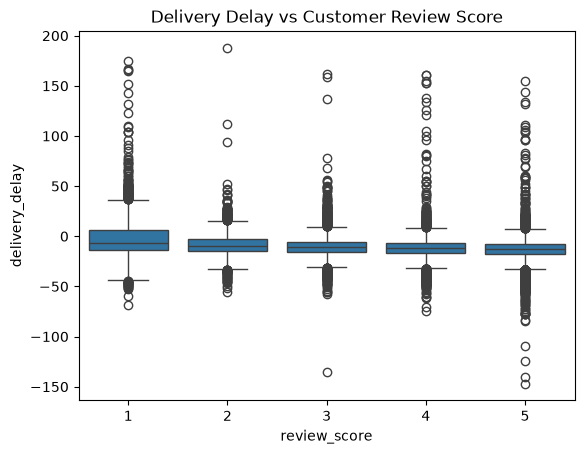

In [24]:
sns.boxplot(x="review_score", y="delivery_delay", data=df_main)
plt.title("Delivery Delay vs Customer Review Score")


In [25]:
# Standard deviation of delay for each review score
df_main.groupby("review_score")["delivery_delay"].std()

review_score
1    16.040544
2    12.677365
3    10.383565
4     9.058151
5     8.157585
Name: delivery_delay, dtype: float64

<Axes: title={'center': 'Standard Deviation of Delivery Delay by Review Score'}, xlabel='Review Score', ylabel='Standard Deviation of Delivery Delay (days)'>

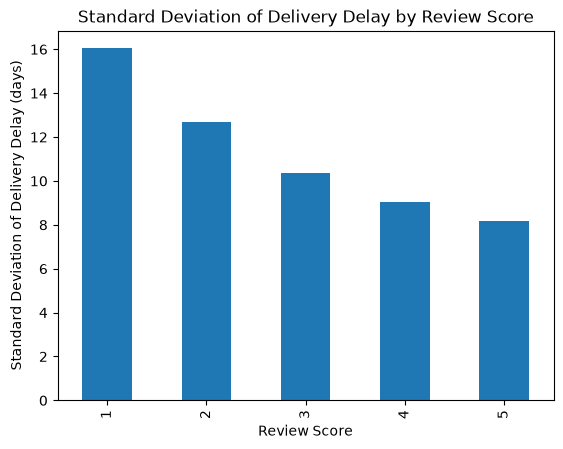

In [26]:
df_main.groupby("review_score")["delivery_delay"].std().plot(
    kind="bar",
    title="Standard Deviation of Delivery Delay by Review Score",
    xlabel="Review Score",
    ylabel="Standard Deviation of Delivery Delay (days)"
)

Another pattern we can also see is the lower the review score, the higher the standard deviation of delivery delays.
This means that delivery delays were much more variable in low reviews and much more consistent in high reviews


# Is there a relationship between location of delivery and the delivery prediction accuracy?

## Learning about the data needed and creating the necessary data sets

In [27]:
df_main.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   review_id                      99224 non-null  str           
 1   order_id                       99224 non-null  str           
 2   review_score                   99224 non-null  int64         
 3   review_comment_title           11568 non-null  str           
 4   review_comment_message         40977 non-null  str           
 5   review_creation_date           99224 non-null  str           
 6   review_answer_timestamp        99224 non-null  str           
 7   customer_id                    99224 non-null  str           
 8   order_status                   99224 non-null  str           
 9   order_purchase_timestamp       99224 non-null  str           
 10  order_approved_at              99068 non-null  str           
 11  order_delivered_carrier_da

In [28]:
df_geolocation.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 38.2 MB


In [29]:
df_geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [30]:
df_main.columns.tolist()

['review_id',
 'order_id',
 'review_score',
 'review_comment_title',
 'review_comment_message',
 'review_creation_date',
 'review_answer_timestamp',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_zip_code_prefix',
 'customer_city',
 'customer_state',
 'order_price',
 'delivery_delay']

In [31]:
# Calculating the average delivery delay for each state
delivery_delay_location = df_main.groupby("customer_zip_code_prefix")["delivery_delay"].mean().reset_index().rename(columns={"delivery_delay": "average_delivery_delay"})

# The geolocation file contains points that are not in Brazil (for example a random road in spain and in the middle of the ocean), so we will filter them out
df_geolocation_brazil = df_geolocation[
    df_geolocation["geolocation_lat"].between(-33.75, 5.27)
    & df_geolocation["geolocation_lng"].between(-73.99, -34.79)
]

# Grouping coordinates
df_geolocation_grouped = df_geolocation_brazil.groupby("geolocation_zip_code_prefix").agg({
    "geolocation_lat": "median",
    "geolocation_lng": "median",
    "geolocation_city": "first",
    "geolocation_state": "first",
}).reset_index()

# Merging the average delivery delay with the grouped geolocation data
df_delivery_delay_location = pd.merge(delivery_delay_location, df_geolocation_grouped, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left")

In [32]:
print(df_geolocation_grouped.columns)
print(df_main.columns)
print(delivery_delay_location.columns)

Index(['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng',
       'geolocation_city', 'geolocation_state'],
      dtype='str')
Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp', 'customer_id', 'order_status',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'customer_unique_id',
       'customer_zip_code_prefix', 'customer_city', 'customer_state',
       'order_price', 'delivery_delay'],
      dtype='str')
Index(['customer_zip_code_prefix', 'average_delivery_delay'], dtype='str')


In [33]:
df_delivery_delay_location.info()
df_delivery_delay_location.head()

<class 'pandas.DataFrame'>
RangeIndex: 14973 entries, 0 to 14972
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   customer_zip_code_prefix     14973 non-null  int64  
 1   average_delivery_delay       14869 non-null  float64
 2   geolocation_zip_code_prefix  14816 non-null  float64
 3   geolocation_lat              14816 non-null  float64
 4   geolocation_lng              14816 non-null  float64
 5   geolocation_city             14816 non-null  str    
 6   geolocation_state            14816 non-null  str    
dtypes: float64(4), int64(1), str(2)
memory usage: 819.0 KB


,customer_zip_code_prefix,average_delivery_delay,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1003,-12.00,1003.0,-23.548977,-46.635313,sao paulo,SP
1,1004,-15.00,1004.0,-23.549535,-46.634771,sao paulo,SP
2,1005,-14.00,1005.0,-23.549612,-46.636532,sao paulo,SP
3,1006,-15.00,1006.0,-23.550317,-46.636225,sao paulo,SP
4,1007,-11.25,1007.0,-23.550349,-46.637342,sao paulo,SP


## Creating the map

In [34]:
# Designing the type of map used
m = folium.Map(
    location=[-14.2, -51.9],
    zoom_start=4,
    tiles="openstreetmap"
)

# Cleaning colour frame for bug fixing
df_delivery_delay_location = df_delivery_delay_location.dropna(
    subset=[
        "average_delivery_delay",
        "geolocation_lat",
        "geolocation_lng"
    ]
)

# Creating colour gradient
limit = df_delivery_delay_location["average_delivery_delay"].abs().max()
colormap = cm.LinearColormap(
    colors=["blue", "white", "red"],
    vmin=-limit,
    vmax=limit,
    caption="Average delivery delay (days)"
)

# Blue is arrived earlier than expected, white is on time, and red is arrived later than expected.

# Adding locations to the map
for _, row in df_delivery_delay_location.iterrows():

    folium.CircleMarker(
        location=[
            row["geolocation_lat"],
            row["geolocation_lng"]
        ],
        radius=5,
        color=colormap(row["average_delivery_delay"]),
        fill=True,
        fill_color=colormap(row["average_delivery_delay"]),
        fill_opacity=0.7,
        popup=f"""
        City: {row["geolocation_city"]}<br>
        State: {row["geolocation_state"]}<br>
        Average delay: {row["average_delivery_delay"]:.2f} days
        """
    ).add_to(m)

colormap.add_to(m)


In [35]:
m.save("delivery_prediction_accuracy_map.html")

From this map, we aren't able to see any specific patterns showing a significant difference in delivery prediction accuracy
What is important to note here is this does not mean that the rural towns get the same speed deliveries as cities, as their predictions may be further ahead in time to compensate for the effort required to deliver the packages

# Is there a relationship between the price and the delivery prediction accuracy?

## Learning about the price of items data distribution

In [36]:
df_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [37]:
df_main = df_main.merge(df_items[["order_id", "price"]], on="order_id", how="left")

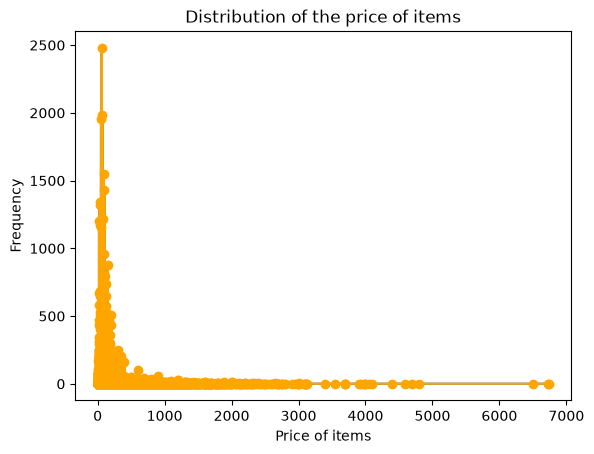

In [38]:
x = df_items["price"].value_counts().sort_index().index
y = df_items["price"].value_counts().sort_index().values
df_items["price"].value_counts().sort_index().plot(
    kind="line",
    title="Distribution of the price of items",
    xlabel="Price of items", 
    ylabel="Frequency")
plt.plot(x, y, marker='o', color='orange', label='Line of Best Fit')

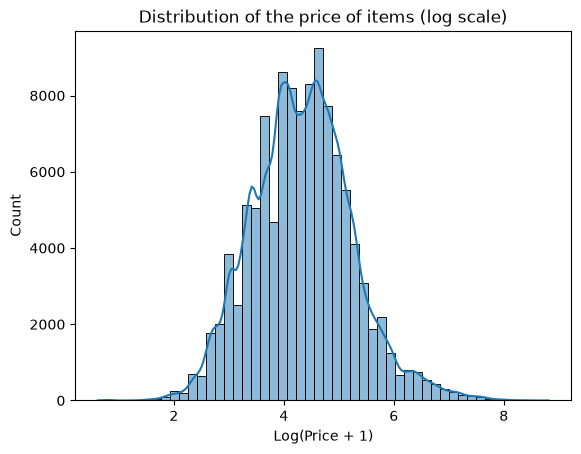

In [39]:
g = sns.histplot(np.log(df_items["price"] + 1), bins = 50, kde=True)
g.set(title="Distribution of the price of items (log scale)", xlabel="Log(Price + 1)", ylabel="Count")
plt.show()


These graphs show that the data is right-skewed where there are is a significantly largern number of low prices items compared to high prices items.
Applying the log function reduced the skeweness of the data bringing it close for normal distribution. This means this data is better for analysis

In [40]:
## Comparing price of items distribution to delivery prediction accuracy

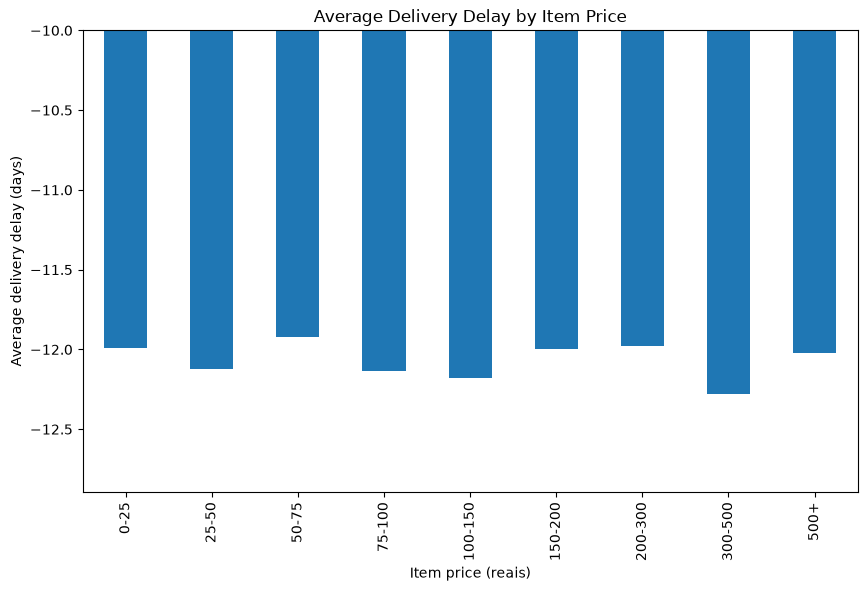

In [41]:
bands = [0, 25, 50, 75, 100, 150, 200, 300, 500, np.inf]
band_labels = ["0-25", "25-50", "50-75", "75-100", "100-150", "150-200", "200-300", "300-500", "500+"]
df_main["price_band"] = pd.cut(df_items["price"], bins=bands, labels=band_labels, include_lowest=True)

delay_by_item_price = df_main.groupby("price_band", observed=True)["delivery_delay"].mean()

plt.figure(figsize=(10, 6))
delay_by_item_price.plot(
    kind="bar",
    title="Average Delivery Delay by Item Price",
    xlabel="Item price (reais)",
    ylabel="Average delivery delay (days)"
)
plt.ylim(top=-10)
plt.show()



This shows that the higher the item price, the earlier the the delivery comes compared to the prediction. This suggests that more expensive items may get prioritised in delivery.

## Learning about price of orders data distribution

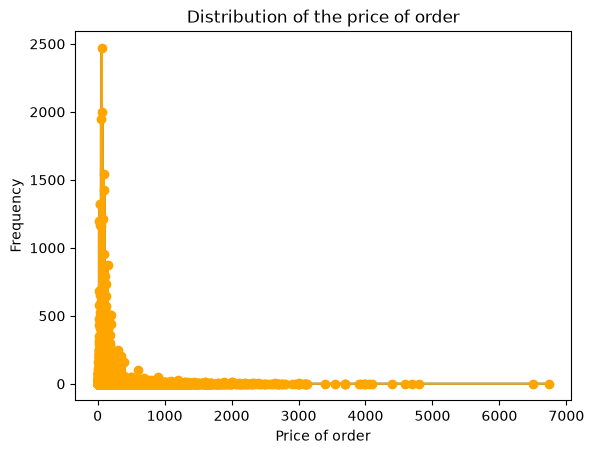

In [42]:
x = df_main["price"].value_counts().sort_index().index
y = df_main["price"].value_counts().sort_index().values
df_main["price"].value_counts().sort_index().plot(
    kind="line",
    title="Distribution of the price of order",
    xlabel="Price of order", 
    ylabel="Frequency")
plt.plot(x, y, marker='o', color='orange', label='Line of Best Fit')

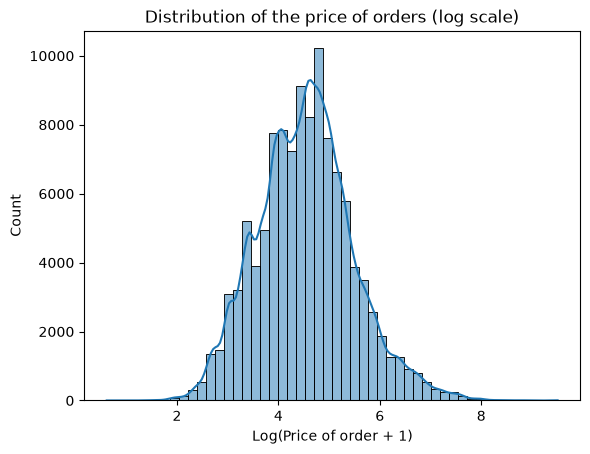

In [43]:
g = sns.histplot(np.log(df_main["order_price"] + 1), bins = 50, kde=True)
g.set(title="Distribution of the price of orders (log scale)", xlabel="Log(Price of order + 1)", ylabel="Count")
plt.show()

This shows a similar pattern to the price of items however the graph is slightly more left skewed this time
This is expected as orders would typically contain a similar distribution to items however more expensive since it would often comprise of multiple items

## Comparing price of orders distribution to delivery prediction accuracy

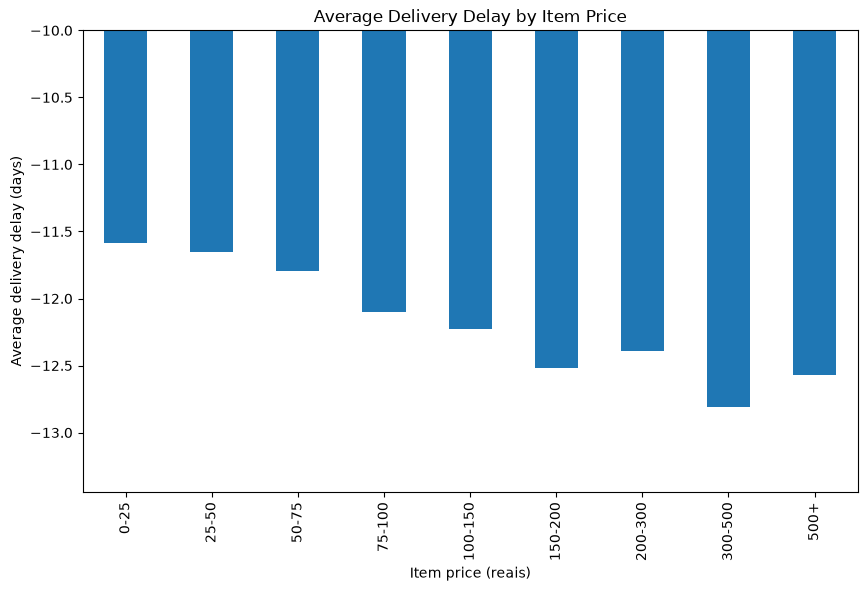

In [44]:
bands = [0, 25, 50, 75, 100, 150, 200, 300, 500, np.inf]
band_labels = ["0-25", "25-50", "50-75", "75-100", "100-150", "150-200", "200-300", "300-500", "500+"]
df_main["price_band"] = pd.cut(df_main["order_price"], bins=bands, labels=band_labels, include_lowest=True)

delay_by_item_price = df_main.groupby("price_band", observed=True)["delivery_delay"].mean()

plt.figure(figsize=(10, 6))
delay_by_item_price.plot(
    kind="bar",
    title="Average Delivery Delay by Item Price",
    xlabel="Item price (reais)",
    ylabel="Average delivery delay (days)"
)
plt.ylim(top=-10)
plt.show()


This shows that the higher the order price, the earlier the the delivery comes compared to the prediction. This suggests that more expensive orders may get prioritised in delivery.

These 2 bar charts show a noticeable difference in delivery delay from item price to order price. However, this is hypothesis tested next and disproven 
What is surprising is that it should be expected that since higher cost items lead to higher prices orders, a similar pattern should be shown.
However, this can be explained by the fact that orders with high priced items may often be paired with several lower prices items.
Also, multi-item orders may have more issues as it comes to deliveries causing more delay.

## Hypthesis testing 

In [ ]:
# Correlation analysis of order price and delivery delay
rho, p = stats.spearmanr(df_main["price"], df_main["delivery_delay"], nan_policy="omit")
print(f"Spearman correlation coefficient for orders: {rho}, p-value: {p}")


# Merge to bring columns into the same dataset for correlation analysis
items_with_delay = df_items.merge(df_main[["order_id", "delivery_delay"]], on="order_id", how="inner")

# Correlation analysis of items price and delivery delay
rho, p = stats.spearmanr(items_with_delay["price"], items_with_delay["delivery_delay"], nan_policy="omit")
print(f"Spearman correlation coefficient for items: {rho}, p-value: {p}")

Spearman correlation coefficient for orders: -0.0293789119835264, p-value: 1.9111256067420553e-22
Spearman correlation coefficient for items: -0.02700738193619531, p-value: 3.9633363590250535e-26


The p-values in both cases are extremely small showing there is a statistically significant relationship between the price of item/order and the delivery delay
However, since the rho values are only slightly negative (-0.029, -0.027), it shows there is only a very small decrease in delivery delay with more expensive items/orders
Also, the rho values are very similar showing no meaningful difference between the relationship of delay of price of item compared to delay of price of order

# Is there a relationship between the weight and volume of the order and the delivery prediction accuracy?

## Organising the data for the prediction model

In [54]:
df_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [66]:
# Cleaning the data from missing rows 
cols = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
df_products_clean = df_products.dropna(subset=cols).copy()

#Calculating the volume of the products
df_products_clean["product_volume_cm3"] = (
    df_products_clean["product_length_cm"] *
    df_products_clean["product_height_cm"] *
    df_products_clean["product_width_cm"]
)


# Merging the product weight, volume, id, and order id into a temporary dataframe
df_prod = df_items[["order_id", "product_id"]].merge(
    df_products_clean[["product_id", "product_weight_g", "product_volume_cm3"]],
    on="product_id", how="inner")

# Grouping by order_id to get the total weight and volume for each order
df_order_size = df_prod.groupby("order_id", as_index=False).agg(
    order_weight_g=("product_weight_g", "sum"),
    order_volume_cm3=("product_volume_cm3", "sum"))

df_model = df_main.merge(df_order_size, on="order_id", how="inner")

In [67]:
df_model = df_model.dropna(subset=["delivery_delay"])   # only orders that actually arrived

df_model["is_late"] = (df_model["delivery_delay"] > 0).astype(int) # Creating an is late column

X = df_model[["order_weight_g", "order_volume_cm3"]]
y = df_model["is_late"]


In [70]:
print("Average amount of late deliveries:", y.mean()) 

Average amount of late deliveries: 0.06466716366347255


## Programming the random forest prediction model

In [72]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, # Model is trained on 80% of the data and will be tested on 20% of the data
    stratify=y, 
    random_state=42
)


In [74]:
rf = RandomForestClassifier(n_estimators=200, # Number of trees in the forest
                            max_depth=8, # Maximum depth of each tree
                            min_samples_leaf=20,
                            class_weight="balanced", 
                            random_state=42, 
                            n_jobs=-1 # Uses all CPU cores
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

## Testing the model and analysing its accuracy

              precision    recall  f1-score   support

           0       0.94      0.63      0.75     20576
           1       0.08      0.46      0.13      1423

    accuracy                           0.61     21999
   macro avg       0.51      0.54      0.44     21999
weighted avg       0.89      0.61      0.71     21999



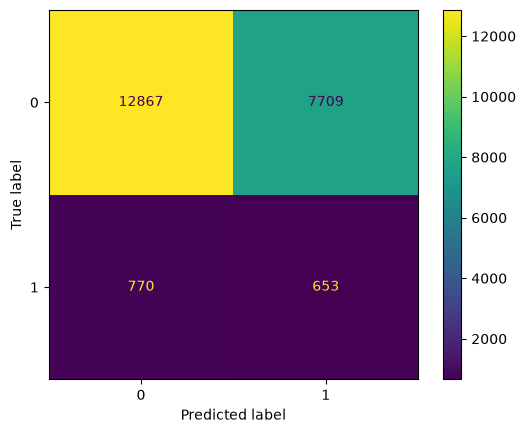

In [86]:
pred = rf.predict(X_test)
print(classification_report(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

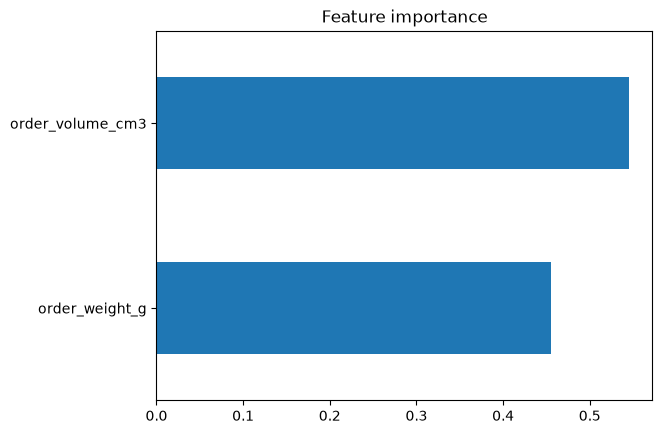

In [ ]:
# Visualising which features are most important in predicting late deliveries
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", title="Feature importance")
plt.show()

This shows that the order volume has a slightly larger affect on the delivery delay than the order weight

In [ ]:
# How well can the model predict late deliveries?
print("Train AUC:", roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1]))
print("Test AUC: ", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))

Train AUC: 0.6508059012360152
Test AUC:  0.5626285876114357


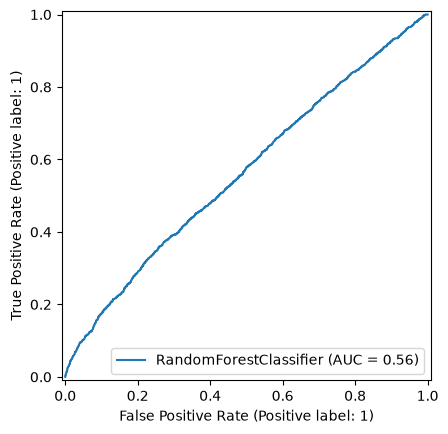

In [85]:
RocCurveDisplay.from_estimator(rf, X_test, y_test)
plt.show()

When tested the AUC is very weak at 0.56 which is not much better than a coin flip showing this model is only slightly better than random guessing.
This shows that volume and weight are not strong drivers of late delivery